# Reference-v2: fixed-window relative-intensity comparison
The original notebook and inputs remain unchanged in reference-v1/raw. Native processing is retained; no universal added Lorentzian or unsupported local baseline. A sigma=1 eV Gaussian is a separate diagnostic. Missing spectra stay missing. These conditional similarity scores do not establish absolute cross-section accuracy.

In [1]:
from pathlib import Path
import sys, subprocess, json
import pandas as pd
from IPython.display import display, Image
root=Path.cwd()
if not (root/"process.py").exists(): root=Path("study/reference_benchmark_v2")
subprocess.run([sys.executable,str(root/"process.py")],check=True)
print("Processing completed")

Processing completed


In [2]:
display(pd.read_csv(root/"before_after_processing_audit.csv"))
print(json.dumps(json.loads((root/"notebook_reconciliation.json").read_text()),indent=2))

{
  "original_notebook_sha256": "f0d052403fcec32b8c97e1577d8d8c3f53cd114e24f3a3b00419679251e8d514",
  "cell1_reproduced_on_actual_Cu_GW_dat": true,
  "Cu_GW_dat_lineage_to_parsed_OUTCAR": "unverified; not substituted or included in method metrics",
  "Cu_PBE_dat_bytes": 0,
  "cell2_status": "unavailable empty original input; separate verified OUTCAR PBE series is explicitly different input",
  "cell3_plus125_and_cell5_reused_intensity": "cannot reproduce a coherent multi-method route after empty PBE input; exploratory offsets are not calibrations",
  "v1_universal_extra_Lorentzian": "removed in v2: no independently established remaining width for these VASP outputs; native CH_SIGMA alone does not resolve instrumental width",
  "sigma1": "exact notebook route saved for actual source; extra Gaussian diagnostic also supplied for parsed spectra without claiming equivalent lineage"
}


,material,method,native_min,native_max,native_nonnegative,v1_processed_min,first_negative_stage,v2_background_correction,native_array_sha256
0,Cu,fdmnes_green,0.000855,0.026373,True,-0.011244,v1 local-background subtraction,none: v1 local window not independently justif...,9170d74a2368858edc025caf9aff6626e58f4f095fb8c7...
1,Cu,fdmnes_fdm,0.000853,0.023422,True,-0.013096,v1 local-background subtraction,none: v1 local window not independently justif...,23898145afe38a19ef503c9b597209e01467f3344ca142...
2,Cu,feff,0.070654,1.203820,True,-0.063637,v1 local-background subtraction,none: v1 local window not independently justif...,e523459cf47372f1ee94908a3f4a0d23e09d07fdd4c80c...
3,Cu,vasp_pbe,0.000000,0.000014,True,-0.021603,v1 local-background subtraction,none: v1 local window not independently justif...,b459eb63fb92f5604d3c3b8f19cc098d88ea17401f6b8a...
4,Cu,vasp_gw,0.000000,0.000025,True,-0.015658,v1 local-background subtraction,none: v1 local window not independently justif...,9eb90d299422cd663c7428a62abb67112dac2d377c35d9...
5,Cu,experiment,-0.001021,1.086502,False,NaN,raw experimental baseline/noise,none: v1 local window not independently justif...,32de3dcd7a02c47a47c5ade45a9e6a97fa80b371c25656...
6,Cu2O,fdmnes_green,0.002730,0.108361,True,-0.007149,v1 local-background subtraction,none: v1 local window not independently justif...,1c204bc18126c216da2d797c0e7f116dc4b0e193bb204a...
7,Cu2O,fdmnes_fdm,0.002667,0.114949,True,-0.006422,v1 local-background subtraction,none: v1 local window not independently justif...,b3da17f7db30febdf582c41e2de783837d85bb3e56df55...
8,Cu2O,feff,0.073679,1.374030,True,-0.346774,v1 local-background subtraction,none: v1 local window not independently justif...,21040125156898a04362ba9fa87b9dfb4fc31cdbb99c00...
9,Cu2O,experiment,-0.001707,1.142217,False,NaN,raw experimental baseline/noise,none: v1 local window not independently justif...,4121cf2d723ebf9602c6a1ef8f0127aee999eda94d3146...


In [3]:
d=pd.read_csv(root/"similarity_metrics.csv")
display(d[d.comparison_type=="Cu_calibrated"])
display(pd.read_csv(root/"unavailable_comparisons.csv"))

,material,method,method_key,processing_version,comparison_type,normalization,energy_min_eV,energy_max_eV,n_points,shift_eV,Gaussian_sigma_added_eV,Gaussian_FWHM_added_eV,Lorentzian_HWHM_added_eV,Lorentzian_FWHM_added_eV,native_processing,cosine_similarity,pearson_r,spearman_rho,rmse
0,Cu,FDMNES green,fdmnes_green,reference-v2,Cu_calibrated,"(I-min)/(max-min), extrema on identical 8980–9...",8980.0,9020.0,201,-0.363691,0.0,0.0,0.0,0.0,native energy-dependent convolution retained,0.997815,0.986582,0.923223,0.055480
4,Cu,FDMNES fdm,fdmnes_fdm,reference-v2,Cu_calibrated,"(I-min)/(max-min), extrema on identical 8980–9...",8980.0,9020.0,201,1.800000,0.0,0.0,0.0,0.0,native energy-dependent convolution retained,0.994186,0.972209,0.761971,0.083876
8,Cu,FEFF,feff,reference-v2,Cu_calibrated,"(I-min)/(max-min), extrema on identical 8980–9...",8980.0,9020.0,201,-8.523168,0.0,0.0,0.0,0.0,native FEFF lifetime/self-energy,0.990959,0.964125,0.909557,0.110047
11,Cu,VASP PBE,vasp_pbe,reference-v2,Cu_calibrated,"(I-min)/(max-min), extrema on identical 8980–9...",8980.0,9020.0,201,115.744827,0.0,0.0,0.0,0.0,"CH_SIGMA=0.1 eV, executable-specific width con...",0.873565,0.427658,0.436362,0.457098
14,Cu,VASP GW,vasp_gw,reference-v2,Cu_calibrated,"(I-min)/(max-min), extrema on identical 8980–9...",8980.0,9020.0,201,124.782401,0.0,0.0,0.0,0.0,"CH_SIGMA=0.1 eV, executable-specific width con...",0.885814,0.517599,0.621287,0.492328
17,Cu2O,FDMNES green,fdmnes_green,reference-v2,Cu_calibrated,"(I-min)/(max-min), extrema on identical 8980–9...",8980.0,9020.0,201,-0.363691,0.0,0.0,0.0,0.0,native energy-dependent convolution retained,0.993313,0.975261,0.920907,0.086124
21,Cu2O,FDMNES fdm,fdmnes_fdm,reference-v2,Cu_calibrated,"(I-min)/(max-min), extrema on identical 8980–9...",8980.0,9020.0,201,1.800000,0.0,0.0,0.0,0.0,native energy-dependent convolution retained,0.988492,0.896006,0.841694,0.113775
25,Cu2O,FEFF,feff,reference-v2,Cu_calibrated,"(I-min)/(max-min), extrema on identical 8980–9...",8980.0,9020.0,201,-8.523168,0.0,0.0,0.0,0.0,native FEFF lifetime/self-energy,0.974336,0.818519,0.587050,0.199886
28,CuO,FDMNES green,fdmnes_green,reference-v2,Cu_calibrated,"(I-min)/(max-min), extrema on identical 8980–9...",8980.0,9020.0,201,-0.363691,0.0,0.0,0.0,0.0,native energy-dependent convolution retained,0.995435,0.958927,0.916097,0.091172
32,CuO,FDMNES fdm,fdmnes_fdm,reference-v2,Cu_calibrated,"(I-min)/(max-min), extrema on identical 8980–9...",8980.0,9020.0,201,1.800000,0.0,0.0,0.0,0.0,raw single CuO site; final convolution absent,0.961728,0.831501,0.829175,0.270200


,material,method,comparison,reason
0,Cu,feff,native_axis,identical full window unavailable; no variable...
1,Cu,vasp_pbe,native_axis,identical full window unavailable; no variable...
2,Cu,vasp_gw,native_axis,identical full window unavailable; no variable...
3,Cu2O,feff,native_axis,identical full window unavailable; no variable...
4,Cu2O,vasp_pbe,NaN,no verified numeric XAS series in source snaps...
5,Cu2O,vasp_gw,NaN,no verified numeric XAS series in source snaps...
6,CuO,feff,native_axis,identical full window unavailable; no variable...
7,CuO,vasp_pbe,NaN,no verified numeric XAS series in source snaps...
8,CuO,vasp_gw,native_axis,identical full window unavailable; no variable...


{
  "fdmnes_green": -0.3636910087921803,
  "fdmnes_fdm": 1.7999999999999794,
  "feff": -8.523168388999759,
  "vasp_pbe": 115.7448265466201,
  "vasp_gw": 124.78240064762257
}


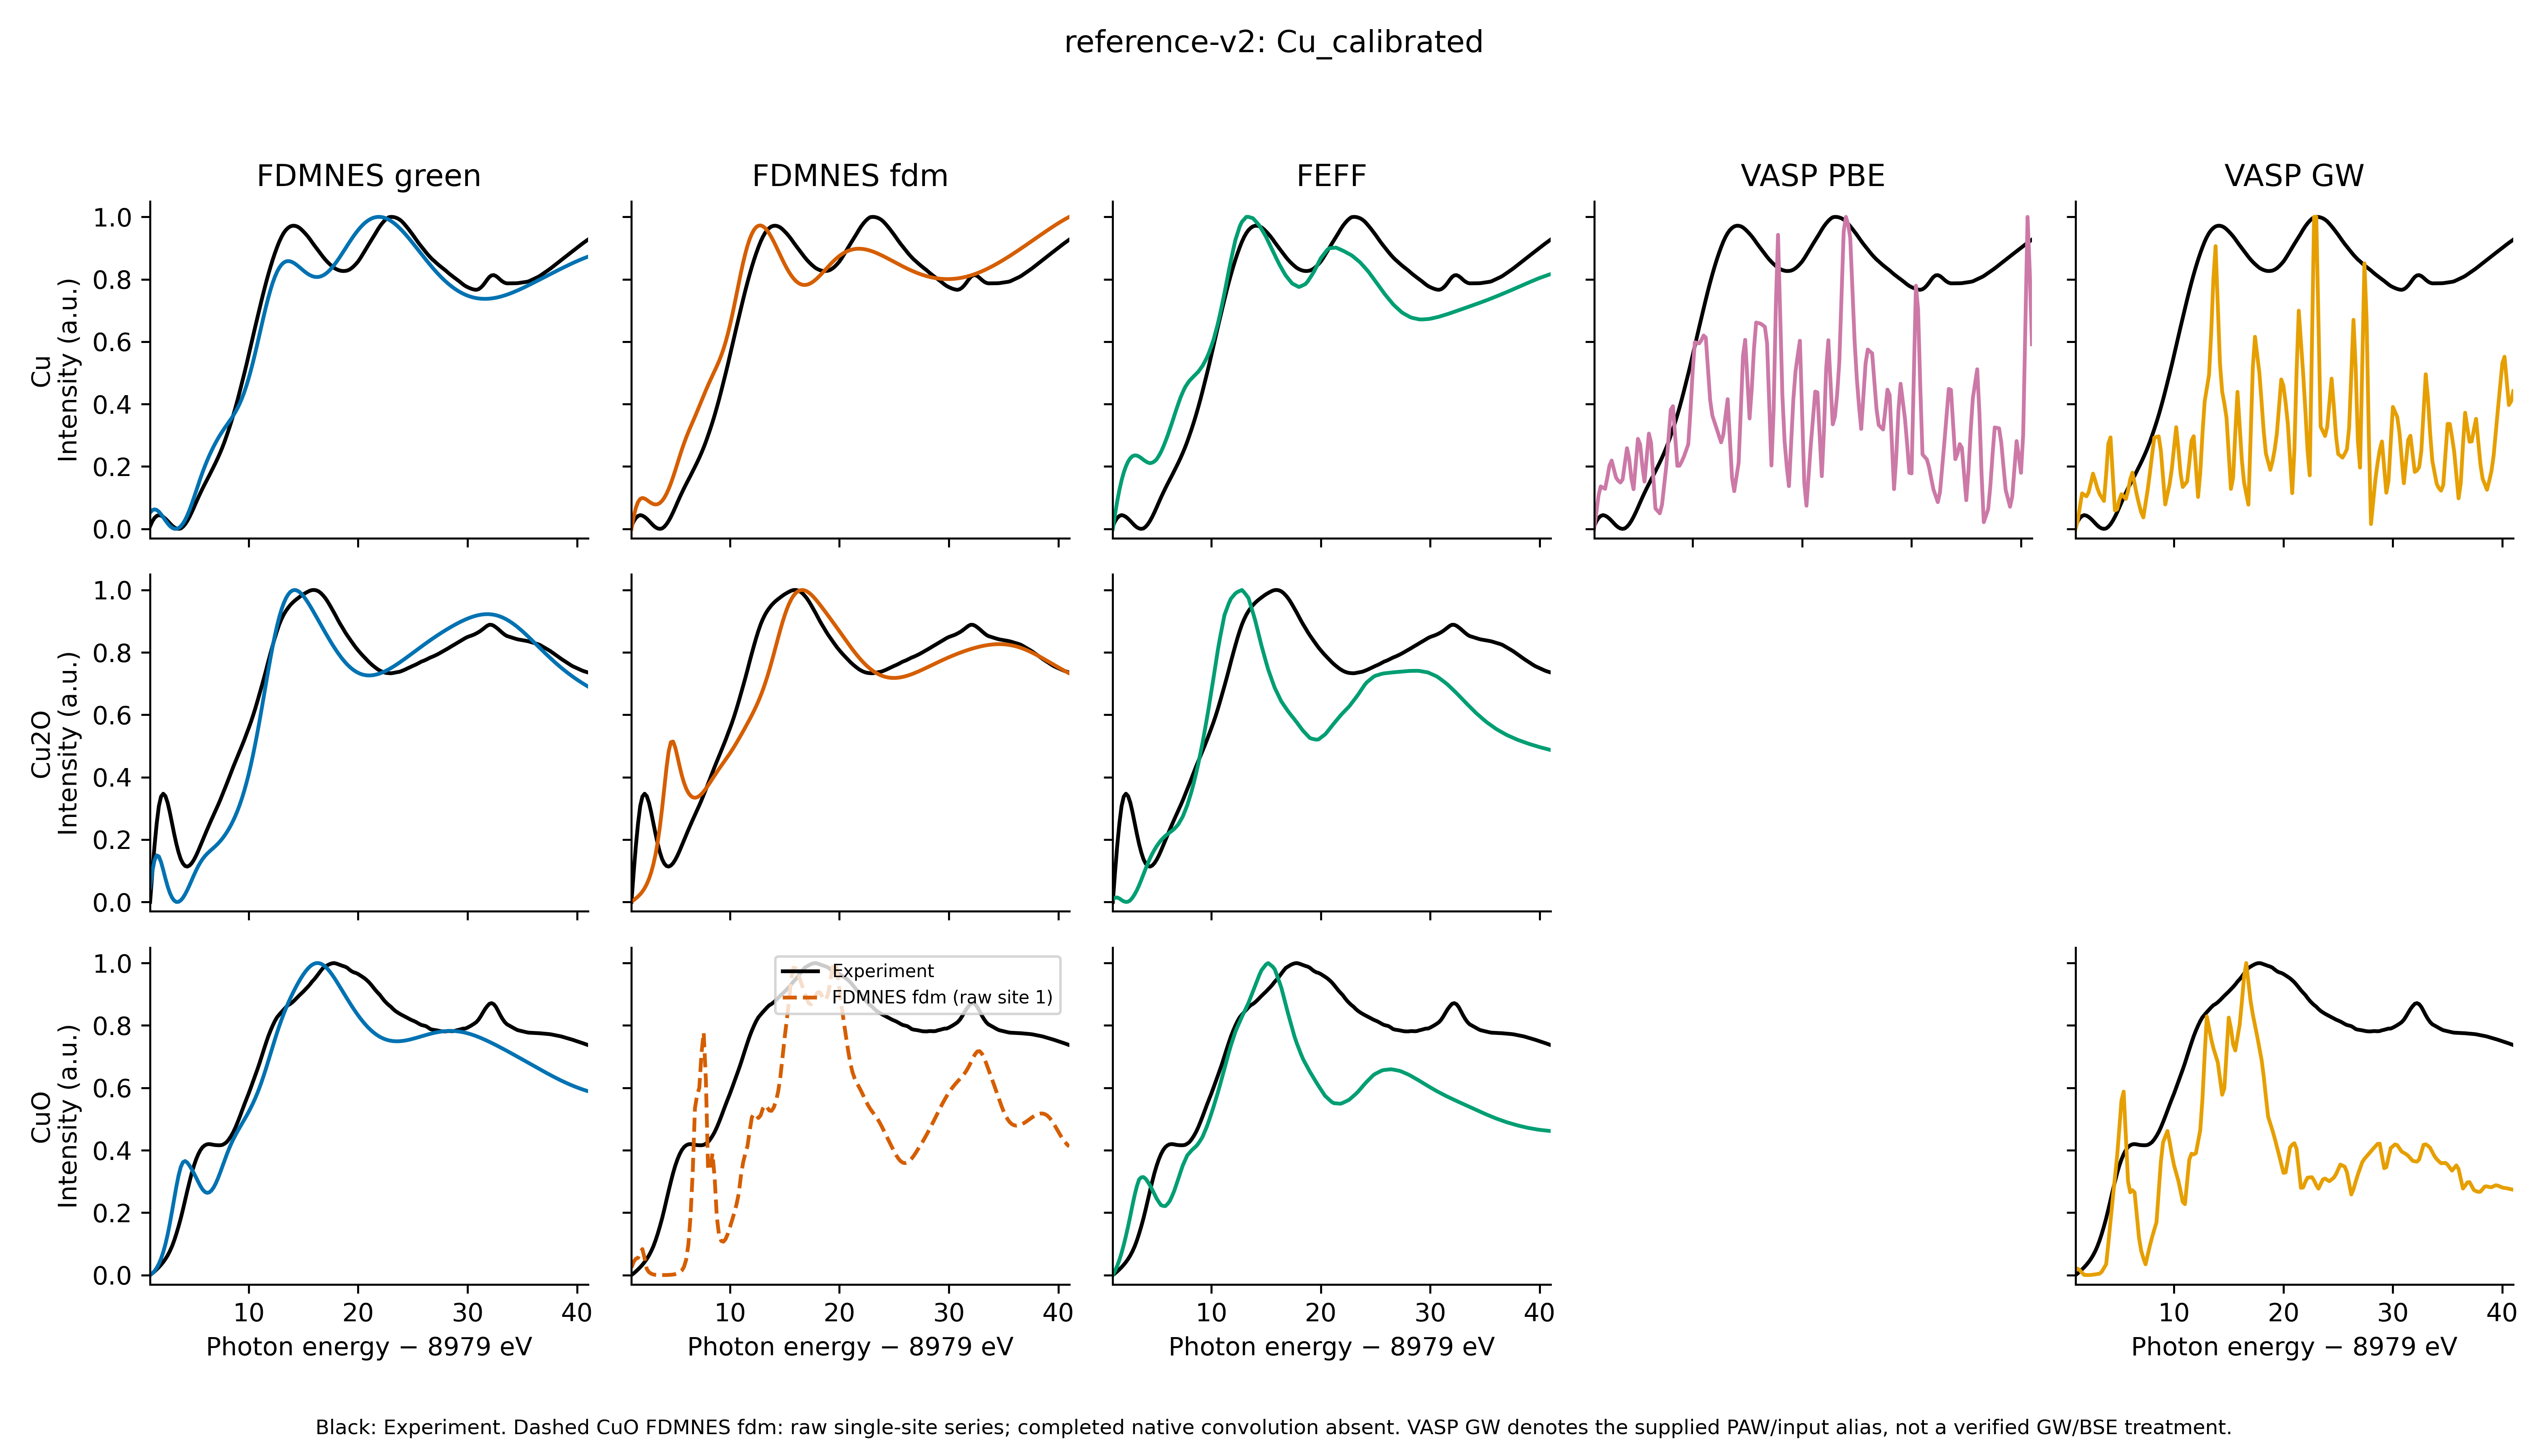

In [4]:
display(Image(filename=str(root/"figures/reference_grid_Cu_calibrated.png"),width=1100))
print(json.dumps(json.loads((root/"settings.json").read_text())["method_Cu_offsets_eV"],indent=2))